# Modul 1 - Dataset Overview

**Project:** Practical EDA with Python  
**Level:** Intermediate  
**Tools:** Python, Pandas, Matplotlib

## Project Challenge

Sebelum mencari insight, kita perlu memahami isi dataset penjualan yang tersedia. Notebook ini menjadi bagian pertama dari Final EDA Report.

> Sebenarnya, seperti apa isi data yang kita miliki?

## Tujuan Pembelajaran

Setelah menyelesaikan notebook ini, kamu mampu:

- memahami struktur dataset;
- mengidentifikasi jumlah baris, kolom, dan tipe data;
- membedakan variabel numerik dan kategorikal;
- menemukan kategori, kota, dan produk yang paling sering muncul;
- membuat visualisasi sederhana;
- menuliskan pertanyaan dan temuan awal dari dataset.

## Project Workflow

`Dataset mentah -> Struktur data -> Jenis variabel -> Eksplorasi awal -> Visualisasi -> Dataset Overview`

## 1. Load Dataset

Dataset berisi informasi transaksi, tanggal, produk, kategori, kota, jumlah barang, harga, dan pendapatan. Setiap baris diharapkan merepresentasikan satu transaksi.

In [16]:
import pandas as pd

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

df = pd.read_csv('data/sales_eda_sample.csv')
df.head(10)

,order_id,date,product,category,city,quantity,price,revenue
0,ORD0001,2026-02-21,Printer,Electronics,SURABAYA,3.0,1800000.0,5400000.0
1,ORD0002,2026-03-28,Laptop,Electronics,yogyakarta,3.0,7500000.0,22500000.0
2,ORD0003,2026-02-22,Printer,Electronics,Yogyakarta,2.0,1890000.0,3780000.0
3,ORD0004,2026-02-02,Keyboard,Accessories,SEMARANG,3.0,405000.0,1215000.0
4,ORD0005,2026-02-28,Keyboard,Accessories,Jakarta,7.0,450000.0,3150000.0
5,ORD0006,2026-02-24,Printer,Electronics,Semarang,5.0,1980000.0,9900000.0
6,ORD0007,2026-02-08,Laptop,Electronics,Yogyakarta,3.0,7500000.0,22500000.0
7,ORD0008,2026-03-31,Laptop,Electronics,NaN,3.0,7875000.0,23625000.0
8,ORD0009,2026-01-08,Laptop,Electronics,yogyakarta,2.0,7875000.0,15750000.0
9,ORD0010,2026-01-06,Mouse,Accessories,semarang,1.0,250000.0,250000.0


In [18]:
df.tail()

,order_id,date,product,category,city,quantity,price,revenue
118,ORD0119,2026-01-01,Desk,Furniture,bandung,6.0,1980000.0,11880000.0
119,ORD0120,2026-03-31,Chair,Furniture,jakarta,5.0,1350000.0,6750000.0
120,ORD0015,2026-03-22,Chair,Furniture,SURABAYA,3.0,1500000.0,4500000.0
121,ORD0048,2026-02-22,Desk,Furniture,Yogyakarta,1.0,2420000.0,2420000.0
122,ORD0103,2026-01-01,Laptop,Electronics,JAKARTA,4.0,8250000.0,33000000.0


## 2. Dataset Structure

Periksa bentuk dataset, nama kolom, dan beberapa baris awal. Gunakan hasilnya untuk menjawab:

- Apakah setiap baris merepresentasikan satu transaksi?
- Kolom apa saja yang tersedia?
- Apakah ada kolom yang terlihat tidak diperlukan?

In [19]:
print(f'Jumlah baris dan kolom: {df.shape}')
print('Nama kolom:')
print(df.columns.tolist())

Jumlah baris dan kolom: (123, 8)
Nama kolom:
['order_id', 'date', 'product', 'category', 'city', 'quantity', 'price', 'revenue']


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  123 non-null    str    
 1   date      123 non-null    str    
 2   product   123 non-null    str    
 3   category  123 non-null    str    
 4   city      118 non-null    str    
 5   quantity  119 non-null    float64
 6   price     121 non-null    float64
 7   revenue   121 non-null    float64
dtypes: float64(3), str(5)
memory usage: 7.8 KB


## 3. Data Types

Variabel numerik digunakan untuk perhitungan, sedangkan variabel kategorikal digunakan untuk pengelompokan. Kolom `date` akan diperlakukan sebagai tanggal agar dapat digunakan dalam analisis waktu pada modul berikutnya.

In [21]:
df['date'] = pd.to_datetime(df['date'] ,errors='coerce', format= 'mixed')

numeric_columns = df.select_dtypes(include='number').columns.tolist()
categorical_columns = df.select_dtypes(include='object').columns.tolist()

print('Variabel numerik:', numeric_columns)
print('Variabel kategorikal:', categorical_columns)
print('Tipe data setelah konversi tanggal:')
df.dtypes

Variabel numerik: ['quantity', 'price', 'revenue']
Variabel kategorikal: ['order_id', 'product', 'category', 'city']
Tipe data setelah konversi tanggal:


C:\Users\20253270\AppData\Local\Temp\ipykernel_12264\2623052209.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns.tolist()


order_id               str
date        datetime64[us]
product                str
category               str
city                   str
quantity           float64
price              float64
revenue            float64
dtype: object

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   order_id  123 non-null    str           
 1   date      123 non-null    datetime64[us]
 2   product   123 non-null    str           
 3   category  123 non-null    str           
 4   city      118 non-null    str           
 5   quantity  119 non-null    float64       
 6   price     121 non-null    float64       
 7   revenue   121 non-null    float64       
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 7.8 KB


## 4. Statistical Summary

Gunakan statistik dasar sebagai petunjuk awal. Jangan langsung menarik kesimpulan hanya dari nilai mean, minimum, atau maksimum.

In [23]:
df.describe()

,date,quantity,price,revenue
count,123,119.000000,1.210000e+02,1.210000e+02
mean,2026-02-15 23:36:35.121951,4.226891,2.257231e+06,7.661983e+06
min,2026-01-01 00:00:00,-2.000000,2.250000e+05,2.500000e+05
25%,2026-01-24 00:00:00,2.000000,4.950000e+05,1.755000e+06
50%,2026-02-20 00:00:00,3.000000,1.620000e+06,4.400000e+06
75%,2026-03-08 12:00:00,5.000000,2.420000e+06,9.000000e+06
max,2026-03-31 00:00:00,100.000000,8.250000e+06,6.600000e+07
std,NaN,9.053922,2.385996e+06,1.073226e+07


## 5. Category Exploration

Pertanyaan: kategori produk apa yang paling banyak muncul dalam dataset?

In [24]:
category_counts = df['category'].value_counts()
category_counts

category
Accessories    48
Electronics    44
Furniture      31
Name: count, dtype: int64

In [25]:
city_counts = df['city'].value_counts()
city_counts

city
Semarang      12
Yogyakarta    11
jakarta       11
SURABAYA       9
 SEMARANG      9
semarang       8
Bandung        8
yogyakarta     7
 Jakarta       7
JAKARTA        7
YOGYAKARTA     6
Jakarta        6
bandung        5
Surabaya       5
surabaya       4
BANDUNG        3
Name: count, dtype: int64

## 6. City Exploration

Pada data nyata, penulisan kategori dapat tidak konsisten, misalnya `Jakarta ` memiliki spasi tambahan atau `yogyakarta` menggunakan huruf kecil. Kita rapikan nama kota sebelum menghitung frekuensinya.

In [ ]:
df['city'].str.strip().str.title()

# strip: menghapus spasi di awal dan akhir string
# title: mengubah huruf pertama setiap kata menjadi huruf kapital
# lower: mengubah semua huruf menjadi huruf kecil
# upper: mengubah semua huruf menjadi huruf kapital

0        Surabaya
1      Yogyakarta
2      Yogyakarta
3        Semarang
4         Jakarta
          ...    
118       Bandung
119       Jakarta
120      Surabaya
121    Yogyakarta
122       Jakarta
Name: city, Length: 123, dtype: str

In [ ]:
df['city'] = df['city'].str.strip().str.title()

city_counts = df['city'].value_counts()
print(f'Jumlah kota: {df["city"].nunique()}')
city_counts

Jumlah kota: 5


city
Jakarta       31
Semarang      29
Yogyakarta    24
Surabaya      18
Bandung       16
Name: count, dtype: int64

## 7. Visualization

Visualisasi membantu membandingkan kategori dan kota dengan lebih cepat.

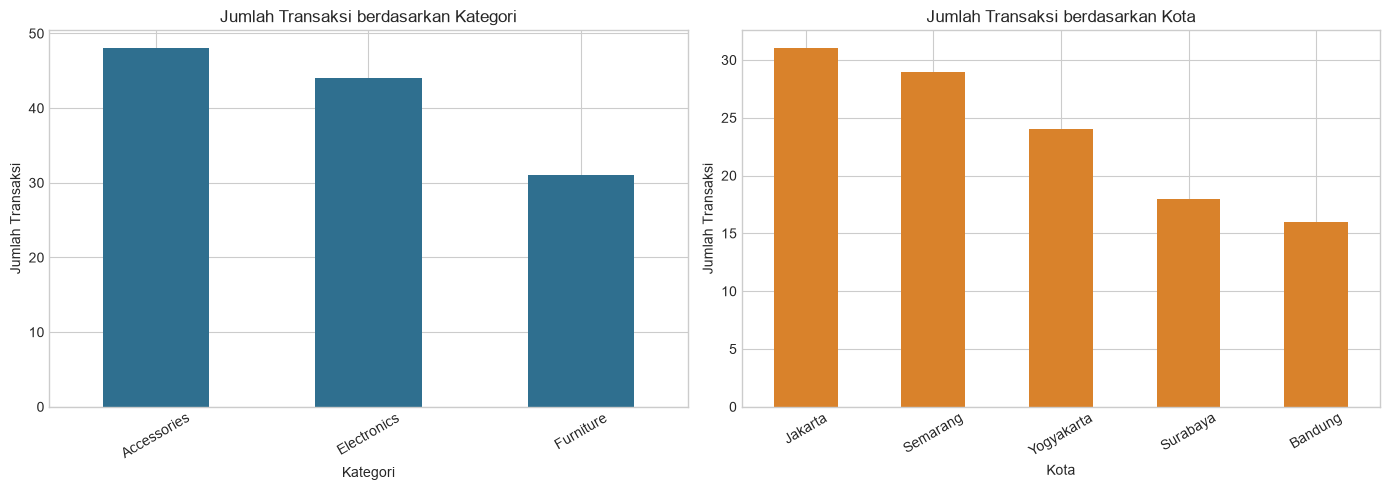

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

category_counts.plot(kind='bar', ax=axes[0], color='#2f6f8f')
axes[0].set_title('Jumlah Transaksi berdasarkan Kategori')
axes[0].set_xlabel('Kategori')
axes[0].set_ylabel('Jumlah Transaksi')
axes[0].tick_params(axis='x', rotation=30)

city_counts.plot(kind='bar', ax=axes[1], color='#d9822b')
axes[1].set_title('Jumlah Transaksi berdasarkan Kota')
axes[1].set_xlabel('Kota')
axes[1].set_ylabel('Jumlah Transaksi')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 8. Independent Challenge

Produk apa yang paling sering muncul dalam transaksi? Jalankan kode berikut, lalu buat visualisasi tambahan secara mandiri.

In [ ]:
product_counts = df['product'].value_counts()
product_counts

## Initial Findings

Kode berikut membantu menghasilkan ringkasan awal dari data aktual. Gunakan hasilnya sebagai dasar untuk menulis temuan dengan kalimatmu sendiri.

In [ ]:
print(f"")
print(f"")
print(f"")

### Tuliskan minimal dua temuan awal

**Finding 1:** ...

**Finding 2:** ...

Pastikan setiap temuan merujuk pada angka atau pola yang terlihat dari tabel maupun grafik.

## Deliverables dan Checklist

Pada akhir Modul 1, notebook ini harus memuat:

- dataset profile: jumlah baris, kolom, tipe data, dan statistik dasar;
- bar chart kategori;
- bar chart kota;
- minimal dua initial findings.

### Checklist

- [ ] Dataset berhasil dibaca
- [ ] Mengetahui jumlah baris dan kolom
- [ ] Mengetahui nama dan tipe setiap variabel
- [ ] Mengetahui statistik dasar
- [ ] Mampu menggunakan `value_counts()`
- [ ] Membuat minimal dua visualisasi
- [ ] Menulis minimal dua initial findings

## Next: Modul 2

Pada modul berikutnya, kita akan memeriksa apakah data memiliki missing value dan masalah kualitas data lainnya.